# Global Solution 2026.2 — MLAM
## Saneamento básico nos municípios brasileiros: urbanização, educação e renda (Censo 2022)

**Desafio CitizenTech — tema: cidades, campo e comunidades.**

**Problema investigado.** Em 2022, cerca de 4 em cada 10 domicílios brasileiros ainda não estavam ligados à rede de esgoto, e a falta de saneamento se concentra em municípios rurais, menos escolarizados e mais pobres. Este notebook usa dados reais do IBGE para medir **quanto o acesso a esgoto, água e coleta de lixo depende de fatores estruturais dos municípios** (grau de urbanização, alfabetização, densidade e renda) e para **identificar os perfis de município com maior risco de saneamento inadequado**.

**Unidade de análise:** município (n = 5.538 após a limpeza).
**Fontes:** IBGE — Censo Demográfico 2022 e PIB dos Municípios 2021, extraídos da API SIDRA (`src/01_coleta_dados.py`) e tratados em `src/02_tratamento_dados.py`.

| Item do enunciado | Seção |
|---|---|
| 02 Distribuição normal | Seção 2 |
| 03 Testes de hipóteses para a média | Seção 3 |
| 04 Análise bivariada | Seção 4 |
| 05 Regressão linear múltipla | Seção 5 |
| 06 Regressão logística binária | Seção 6 |

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
RES = {}  # resultados numéricos usados no relatório em PDF

def salvar(nome):
    plt.savefig(FIG / f"{nome}.png", dpi=150, bbox_inches="tight")

ROTULOS = {
    "pct_pop_urbana": "População urbana (%)",
    "pct_esgoto_rede": "Domicílios ligados à rede de esgoto (%)",
    "pct_agua_rede": "Domicílios com água da rede geral (%)",
    "pct_lixo_coletado": "Domicílios com lixo coletado (%)",
    "taxa_alfabetizacao": "Taxa de alfabetização 15+ anos (%)",
    "log_pib_per_capita": "log10(PIB per capita)",
    "log_densidade": "log10(densidade hab/km²)",
    "pct_vab_agro": "Participação da agropecuária no VAB (%)",
}

df = pd.read_csv(RAIZ / "data" / "processed" / "base_saneamento_municipios_2022.csv", dtype={"codigo_ibge": str})
print(df.shape)
df.head()

(5538, 18)


,codigo_ibge,municipio,uf,regiao,populacao,area_km2,densidade_hab_km2,pct_pop_urbana,pct_esgoto_rede,pct_agua_rede,pct_lixo_coletado,taxa_alfabetizacao,pib_mil_reais,pib_per_capita,pct_vab_agro,log_pib_per_capita,log_densidade,esgoto_adequado
0,1100015,Alta Floresta D'Oeste,RO,Norte,"21,494.0000","7,067.1270",3.0400,60.3500,0.4700,26.4800,61.4800,91.5900,734467,"34,170.7918",45.4785,4.5337,0.4829,0
1,1100023,Ariquemes,RO,Norte,"96,833.0000","4,426.5710",21.8800,86.7000,1.9900,54.3400,90.4200,94.0800,3211294,"33,163.2192",10.4982,4.5207,1.3400,0
2,1100031,Cabixi,RO,Norte,"5,351.0000","1,314.3520",4.0700,53.1900,1.5800,39.3000,61.0600,89.8200,238414,"44,555.0364",60.1436,4.6489,0.6096,0
3,1100049,Cacoal,RO,Norte,"86,887.0000","3,793.0000",22.9100,82.7600,67.1900,80.0700,85.6600,93.7100,2792506,"32,139.5145",14.1749,4.5070,1.3600,1
4,1100056,Cerejeiras,RO,Norte,"15,890.0000","2,783.3000",5.7100,88.8400,57.9900,49.4800,87.0400,92.1500,743062,"46,762.8697",24.8202,4.6699,0.7566,1


## 1. Descrição da base de dados

| Variável | Descrição | Fonte (tabela SIDRA) |
|---|---|---|
| `populacao`, `area_km2`, `densidade_hab_km2` | População residente, área e densidade | Censo 2022 (4714) |
| `pct_pop_urbana` | % da população em situação urbana | Censo 2022 (9923) |
| `pct_esgoto_rede` | % de domicílios com esgoto na rede geral/pluvial ou fossa ligada à rede | Censo 2022 (6805) |
| `pct_agua_rede` | % de domicílios ligados à rede geral de água e que a usam como forma principal | Censo 2022 (6803) |
| `pct_lixo_coletado` | % de domicílios com lixo coletado | Censo 2022 (6892) |
| `taxa_alfabetizacao` | Taxa de alfabetização das pessoas com 15 anos ou mais | Censo 2022 (9543) |
| `pib_per_capita` | PIB 2021 / população 2022 (R$) | PIB dos Municípios (5938) |
| `pct_vab_agro` | Participação da agropecuária no valor adicionado bruto | PIB dos Municípios (5938) |
| `log_pib_per_capita`, `log_densidade` | Logaritmo base 10 (reduz a assimetria) | derivadas |
| `esgoto_adequado` | 1 se ≥ 50% dos domicílios estão ligados à rede de esgoto, 0 caso contrário | derivada |

In [2]:
VARS = ["pct_esgoto_rede", "pct_agua_rede", "pct_lixo_coletado", "pct_pop_urbana",
        "taxa_alfabetizacao", "pib_per_capita", "pct_vab_agro", "densidade_hab_km2"]
desc = df[VARS].describe().T
desc["cv_%"] = 100 * desc["std"] / desc["mean"]
desc

,count,mean,std,min,25%,50%,75%,max,cv_%
pct_esgoto_rede,"5,538.0000",37.9215,32.9829,0.0300,4.1500,32.6150,67.8875,99.9500,86.9766
pct_agua_rede,"5,538.0000",71.9024,19.3384,0.2500,60.8025,75.8850,87.0000,100.0000,26.8954
pct_lixo_coletado,"5,538.0000",80.3797,17.3261,1.6800,69.5250,85.2350,94.8300,100.0000,21.5553
pct_pop_urbana,"5,538.0000",69.1752,20.0749,7.3300,54.2225,70.9600,86.1200,100.0000,29.0204
taxa_alfabetizacao,"5,538.0000",88.2342,7.5436,63.1900,82.1025,90.6550,94.4400,99.1000,8.5495
pib_per_capita,"5,538.0000","34,518.0927","39,640.2838","5,697.2809","13,675.6089","24,631.9638","41,619.6060","919,482.3680",114.8391
pct_vab_agro,"5,538.0000",23.8624,18.7941,-41.9012,8.7082,19.0087,36.2706,93.4980,78.7600
densidade_hab_km2,"5,538.0000",116.5851,596.6443,0.1500,11.3725,24.4600,53.8825,"13,416.8100",511.7672


In [3]:
regioes = df.groupby("regiao").agg(
    municipios=("municipio", "count"),
    esgoto_rede=("pct_esgoto_rede", "mean"),
    agua_rede=("pct_agua_rede", "mean"),
    lixo_coletado=("pct_lixo_coletado", "mean"),
    urbana=("pct_pop_urbana", "mean"),
    alfabetizacao=("taxa_alfabetizacao", "mean"),
    pct_esgoto_adequado=("esgoto_adequado", "mean"),
).sort_values("esgoto_rede")
regioes["pct_esgoto_adequado"] *= 100
RES["regioes"] = regioes.round(1).reset_index().to_dict(orient="records")
regioes.round(1)

,municipios,esgoto_rede,agua_rede,lixo_coletado,urbana,alfabetizacao,pct_esgoto_adequado
regiao,,,,,,,
Norte,442,7.5000,53.5000,66.4000,63.0000,87.7000,2.3000
Centro-Oeste,466,20.8000,73.6000,81.7000,76.3000,91.2000,16.3000
Nordeste,1776,24.7000,67.7000,71.0000,61.1000,79.6000,18.4000
Sul,1186,29.9000,74.3000,86.9000,67.0000,94.4000,28.5000
Sudeste,1668,70.6000,79.1000,89.1000,78.9000,92.4000,80.9000


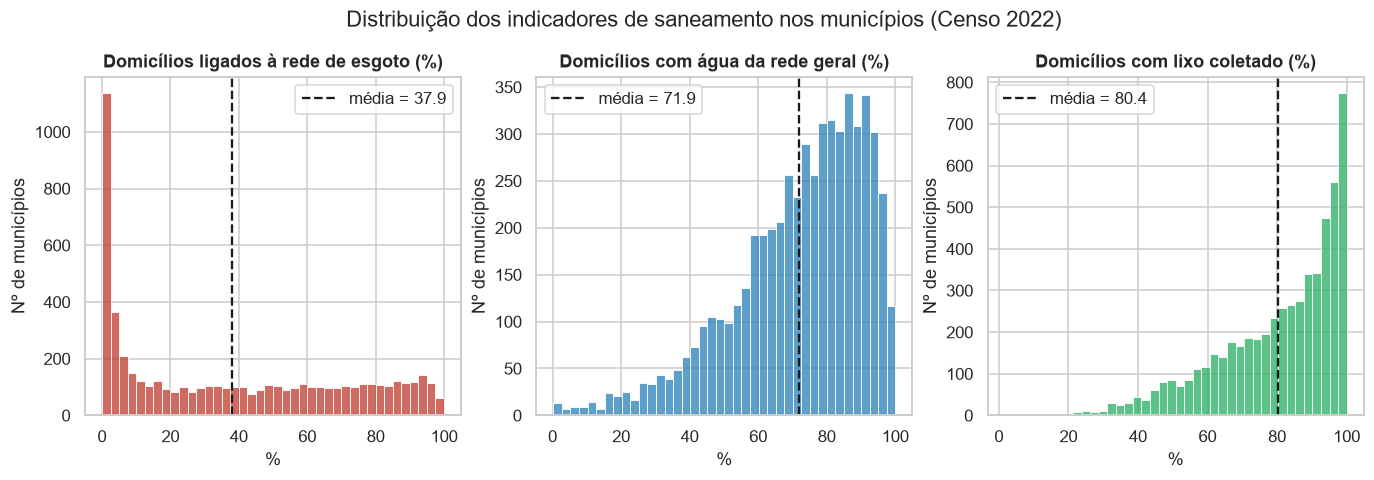

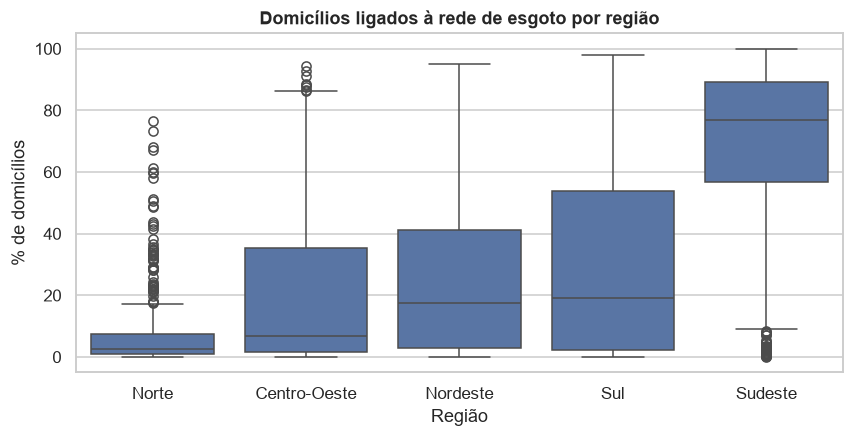

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v, c in zip(ax, ["pct_esgoto_rede", "pct_agua_rede", "pct_lixo_coletado"], ["#c0392b", "#2980b9", "#27ae60"]):
    sns.histplot(df[v], bins=40, ax=a, color=c)
    a.axvline(df[v].mean(), color="k", ls="--", label=f"média = {df[v].mean():.1f}")
    a.set_title(ROTULOS[v]); a.set_xlabel("%"); a.set_ylabel("Nº de municípios"); a.legend()
plt.suptitle("Distribuição dos indicadores de saneamento nos municípios (Censo 2022)", y=1.03)
salvar("01_distribuicao_saneamento"); plt.show()

ordem = regioes.index.tolist()
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="regiao", y="pct_esgoto_rede", order=ordem)
plt.title("Domicílios ligados à rede de esgoto por região")
plt.xlabel("Região"); plt.ylabel("% de domicílios")
salvar("02_esgoto_por_regiao"); plt.show()

RES["n"] = int(len(df))
RES["media_esgoto"] = float(df.pct_esgoto_rede.mean())
RES["mediana_esgoto"] = float(df.pct_esgoto_rede.median())
RES["pct_mun_esgoto_adequado"] = float(100 * df.esgoto_adequado.mean())
RES["mun_esgoto_abaixo_10"] = float(100 * (df.pct_esgoto_rede < 10).mean())

**Leitura inicial.** Coleta de lixo e água encanada estão bem mais difundidas que o esgoto. O esgoto tem distribuição muito dispersa (CV elevado), com muitos municípios perto de 0% e outros perto de 100%, e há forte desigualdade regional: Norte e Nordeste têm as menores coberturas e o Sudeste a maior.

## 2. Distribuição Normal de Probabilidade (item 02)

Variável escolhida: **taxa de alfabetização das pessoas de 15 anos ou mais (`taxa_alfabetizacao`)**, assumida como $X \sim N(\mu, \sigma)$, com $\mu$ e $\sigma$ calculados sobre os 5.538 municípios (tratados como a população).

Critério de classificação do evento quanto ao resultado probabilístico:

| Probabilidade | Classificação |
|---|---|
| P = 0 | Evento impossível |
| 0 < P < 0,5 | Evento improvável (pouco provável) |
| P = 0,5 | Evento equiprovável (tão provável quanto improvável) |
| 0,5 < P < 1 | Evento provável |
| P = 1 | Evento certo |

In [5]:
def classificar(p):
    if np.isclose(p, 0): return "Evento impossível"
    if np.isclose(p, 1): return "Evento certo"
    if np.isclose(p, 0.5, atol=5e-4): return "Evento equiprovável (50%)"
    return "Evento improvável (pouco provável)" if p < 0.5 else "Evento provável"

X = df["taxa_alfabetizacao"]
mu, sigma, mediana = X.mean(), X.std(ddof=0), X.median()

p_a = stats.norm.cdf(mu, loc=mu, scale=sigma)          # P(X < média)
p_b = 1 - stats.norm.cdf(mediana, loc=mu, scale=sigma)  # P(X > mediana)

print(f"Média = {mu:.4f} | Mediana = {mediana:.4f} | Desvio padrão = {sigma:.4f}")
print(f"a) P(X < {mu:.2f}) = {p_a:.4f} ({100*p_a:.2f}%) -> {classificar(p_a)}")
print(f"b) P(X > {mediana:.2f}) = {p_b:.4f} ({100*p_b:.2f}%) -> {classificar(p_b)}")
RES["normal"] = dict(variavel="taxa_alfabetizacao", media=mu, mediana=mediana, sigma=sigma,
                     p_a=p_a, class_a=classificar(p_a), p_b=p_b, class_b=classificar(p_b))

Média = 88.2342 | Mediana = 90.6550 | Desvio padrão = 7.5429
a) P(X < 88.23) = 0.5000 (50.00%) -> Evento equiprovável (50%)
b) P(X > 90.66) = 0.3741 (37.41%) -> Evento improvável (pouco provável)


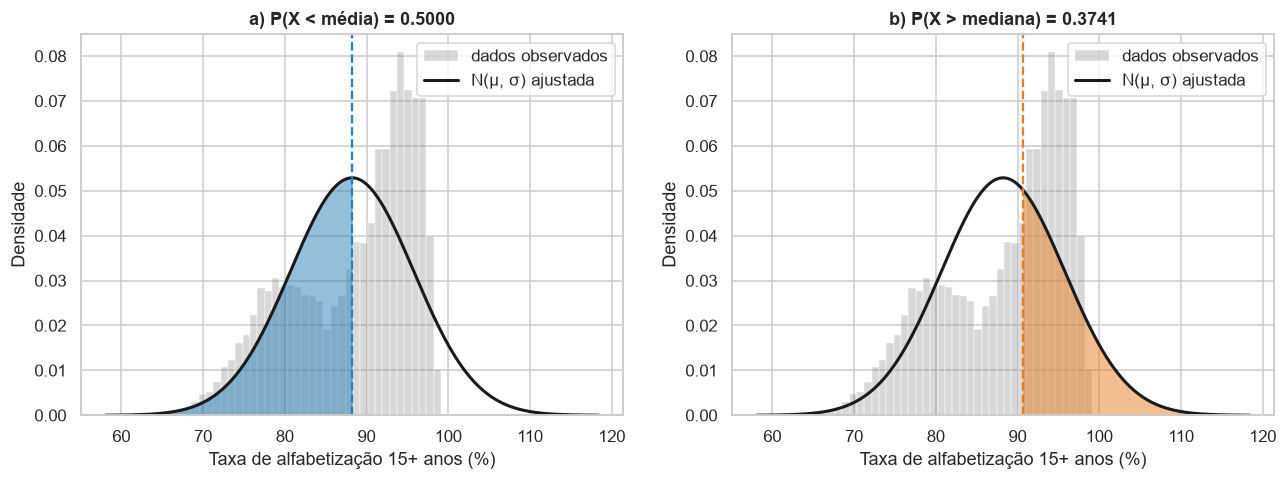

In [6]:
xs = np.linspace(mu - 4*sigma, mu + 4*sigma, 500)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, lim, titulo, cor, cond in [
    (ax[0], mu, f"a) P(X < média) = {p_a:.4f}", "#2980b9", xs <= mu),
    (ax[1], mediana, f"b) P(X > mediana) = {p_b:.4f}", "#e67e22", xs >= mediana)]:
    a.hist(X, bins=40, density=True, alpha=.3, color="gray", label="dados observados")
    a.plot(xs, stats.norm.pdf(xs, mu, sigma), "k", lw=2, label="N(μ, σ) ajustada")
    a.fill_between(xs, stats.norm.pdf(xs, mu, sigma), where=cond, color=cor, alpha=.5)
    a.axvline(lim, color=cor, ls="--")
    a.set_title(titulo); a.set_xlabel(ROTULOS["taxa_alfabetizacao"]); a.set_ylabel("Densidade"); a.legend()
salvar("03_distribuicao_normal"); plt.show()

**Interpretação.**
- **a)** Em toda distribuição normal a média é o centro de simetria, então $P(X<\mu)=0{,}5$: é um **evento equiprovável**. Sob a hipótese de normalidade, metade dos municípios teria alfabetização abaixo da média nacional dos municípios.
- **b)** A mediana observada (≈ 90,7%) é **maior** que a média (≈ 88,2%). A distribuição real é **assimétrica à esquerda**: um grupo de municípios, sobretudo do Nordeste, tem alfabetização muito baixa e puxa a média para baixo. No modelo normal, $P(X > \text{mediana})$ fica abaixo de 50% (**evento improvável/pouco provável**). Nos dados reais essa proporção é 50% por definição da mediana.
- **Limitação:** essa diferença mostra que a hipótese de normalidade é só uma aproximação para essa variável, e as probabilidades devem ser lidas com essa ressalva.

## 3. Testes de hipóteses para a média (item 03)

Variável: **% de domicílios com água da rede geral (`pct_agua_rede`)**, assumida normal.
A **média populacional de referência** $\mu_0$ e o **desvio padrão de referência** $\sigma$ são calculados sobre todos os municípios. As amostras aleatórias simples são sorteadas com semente fixa (`random_state`) para garantir a reprodutibilidade. Como $\sigma$ é conhecido, usa-se o **teste Z**:

$$Z = \frac{\bar{x} - \mu_0}{\sigma/\sqrt{n}}$$

In [7]:
V = "pct_agua_rede"
mu0, sig = df[V].mean(), df[V].std(ddof=0)
print(f"Média populacional de referência μ0 = {mu0:.4f} | desvio padrão populacional σ = {sig:.4f}")

def teste_z(n, alfa, cauda, seed):
    amostra = df[V].sample(n=n, random_state=seed)
    xbar = amostra.mean()
    ep = sig / np.sqrt(n)
    z = (xbar - mu0) / ep
    if cauda == "esquerda":
        zc = stats.norm.ppf(alfa); p = stats.norm.cdf(z); rejeita = z < zc
        h1 = "μ < μ0"
    else:
        zc = stats.norm.ppf(1 - alfa); p = 1 - stats.norm.cdf(z); rejeita = z > zc
        h1 = "μ > μ0"
    return dict(n=n, alfa=alfa, cauda=cauda, h1=h1, seed=seed, xbar=xbar, mu0=mu0, sigma=sig,
                erro_padrao=ep, z=z, z_critico=zc, p_valor=p, rejeita_h0=bool(rejeita))

ta = teste_z(n=20, alfa=0.06, cauda="esquerda", seed=7)
tb = teste_z(n=25, alfa=0.09, cauda="direita", seed=7)
for nome, t in [("a)", ta), ("b)", tb)]:
    print(f"\n{nome} H0: μ = {t['mu0']:.2f}   H1: {t['h1']}   (α = {t['alfa']:.0%}, n = {t['n']})")
    print(f"   x̄ = {t['xbar']:.4f} | EP = {t['erro_padrao']:.4f} | Z = {t['z']:.4f} | Z crítico = {t['z_critico']:.4f} | p-valor = {t['p_valor']:.4f}")
    print("   Decisão:", "REJEITA H0" if t["rejeita_h0"] else "NÃO rejeita H0")
RES["teste_a"], RES["teste_b"] = ta, tb

Média populacional de referência μ0 = 71.9024 | desvio padrão populacional σ = 19.3367

a) H0: μ = 71.90   H1: μ < μ0   (α = 6%, n = 20)
   x̄ = 78.5535 | EP = 4.3238 | Z = 1.5383 | Z crítico = -1.5548 | p-valor = 0.9380
   Decisão: NÃO rejeita H0

b) H0: μ = 71.90   H1: μ > μ0   (α = 9%, n = 25)
   x̄ = 79.3392 | EP = 3.8673 | Z = 1.9230 | Z crítico = 1.3408 | p-valor = 0.0272
   Decisão: REJEITA H0


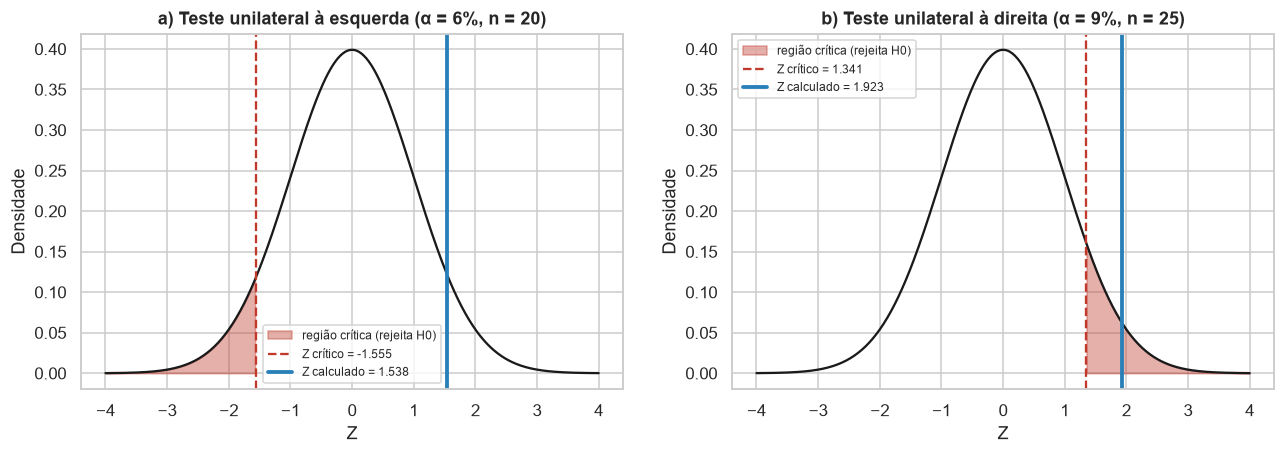

In [8]:
zs = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, t, titulo in [(ax[0], ta, "a) Teste unilateral à esquerda (α = 6%, n = 20)"),
                     (ax[1], tb, "b) Teste unilateral à direita (α = 9%, n = 25)")]:
    a.plot(zs, stats.norm.pdf(zs), "k")
    regiao = zs <= t["z_critico"] if t["cauda"] == "esquerda" else zs >= t["z_critico"]
    a.fill_between(zs, stats.norm.pdf(zs), where=regiao, color="#c0392b", alpha=.4, label="região crítica (rejeita H0)")
    a.axvline(t["z_critico"], color="#c0392b", ls="--", label=f"Z crítico = {t['z_critico']:.3f}")
    a.axvline(t["z"], color="#2980b9", lw=2.5, label=f"Z calculado = {t['z']:.3f}")
    a.set_title(titulo); a.set_xlabel("Z"); a.set_ylabel("Densidade"); a.legend(fontsize=8)
salvar("04_testes_hipotese"); plt.show()

**Interpretação.**
- **a)** $H_0: \mu = 71{,}90\%$ contra $H_1: \mu < 71{,}90\%$ ($\alpha = 6\%$, $n = 20$). A média da amostra sorteada (≈ 78,6%) ficou **acima** da referência, então $Z \approx +1{,}54$ está do lado oposto à região crítica ($Z < -1{,}555$) e o p-valor é ≈ 0,94. **Não se rejeita $H_0$**: não há evidência de que a média da cobertura de água seja menor que a referência nacional.
- **b)** $H_0: \mu = 71{,}90\%$ contra $H_1: \mu > 71{,}90\%$ ($\alpha = 9\%$, $n = 25$). Com $\bar{x} \approx 79{,}3\%$, $Z \approx 1{,}92 > Z_c \approx 1{,}341$ e p-valor ≈ 0,027 < 0,09. **Rejeita-se $H_0$**: a amostra indica média de cobertura de água **maior** que a referência.
- **Leitura prática:** como $\mu_0$ é a média de todos os municípios, o resultado de (b) é um **erro tipo I** possível: com α = 9%, cerca de 9 em cada 100 amostras aleatórias levariam à rejeição mesmo com $H_0$ verdadeira. Isso mostra ao gestor que conclusões tiradas de amostras pequenas (20–25 municípios) dependem do nível de significância e da amostra sorteada, e que é preferível usar a base completa sempre que ela estiver disponível.

## 4. Análise bivariada (item 04)

**Pergunta:** municípios mais urbanizados têm maior cobertura de coleta de lixo?
- $X$ = `pct_pop_urbana` (% da população urbana)
- $Y$ = `pct_lixo_coletado` (% de domicílios com lixo coletado)

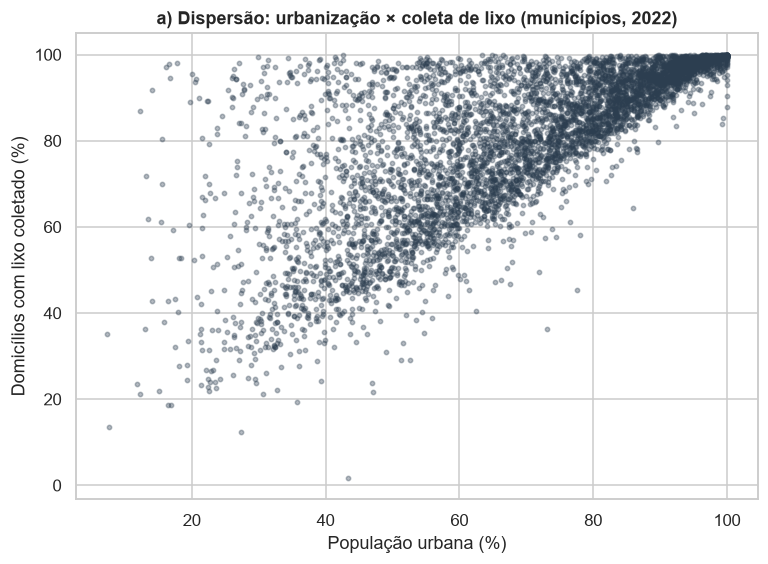

In [9]:
x, y = df["pct_pop_urbana"], df["pct_lixo_coletado"]
plt.figure(figsize=(8, 5.5))
plt.scatter(x, y, s=8, alpha=.35, color="#2c3e50")
plt.title("a) Dispersão: urbanização × coleta de lixo (municípios, 2022)")
plt.xlabel("População urbana (%)"); plt.ylabel("Domicílios com lixo coletado (%)")
salvar("05_dispersao_bivariada"); plt.show()

**a) Interpretação do gráfico de dispersão:** a nuvem de pontos sobe da esquerda para a direita, o que indica **associação positiva**: quanto maior a urbanização, maior a coleta de lixo. A dispersão é maior entre municípios pouco urbanizados (a coleta varia muito no meio rural) e diminui perto de 100% de urbanização, onde quase todos se aproximam da coleta universal. Isso é um sinal de **heterocedasticidade**.

In [10]:
cov_xy = np.cov(x, y, ddof=1)[0, 1]
r, p_r = stats.pearsonr(x, y)
print(f"b) Covariância amostral = {cov_xy:.4f}")
print(f"   Correlação de Pearson r = {r:.4f} (p-valor = {p_r:.2e})")
RES["biv"] = dict(cov=cov_xy, r=r, p_r=p_r)

b) Covariância amostral = 257.2454
   Correlação de Pearson r = 0.7396 (p-valor = 0.00e+00)


**b) Interpretação:** a **covariância positiva** confirma que as variáveis crescem juntas, mas seu valor depende das unidades (%²) e por isso não mede a força da relação. O **coeficiente de Pearson** (entre −1 e 1) indica uma **correlação positiva forte**, já que r está acima de 0,7. O p-valor praticamente nulo mostra que essa correlação não se deve ao acaso.

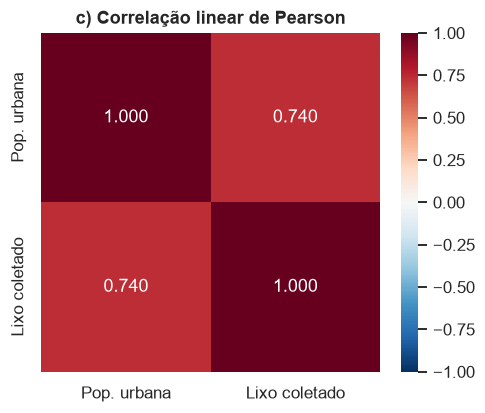

In [11]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[["pct_pop_urbana", "pct_lixo_coletado"]].corr(), annot=True, fmt=".3f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True,
            xticklabels=["Pop. urbana", "Lixo coletado"], yticklabels=["Pop. urbana", "Lixo coletado"])
plt.title("c) Correlação linear de Pearson")
salvar("06_correlacao_bivariada"); plt.show()

**c) Interpretação:** o mapa de calor mostra r ≈ 0,74 fora da diagonal (cor vermelha intensa), uma **correlação linear positiva forte**. A diagonal vale 1 porque é a correlação de cada variável com ela mesma.

d) Equação: Ŷ = 36.2236 + 0.6383·X


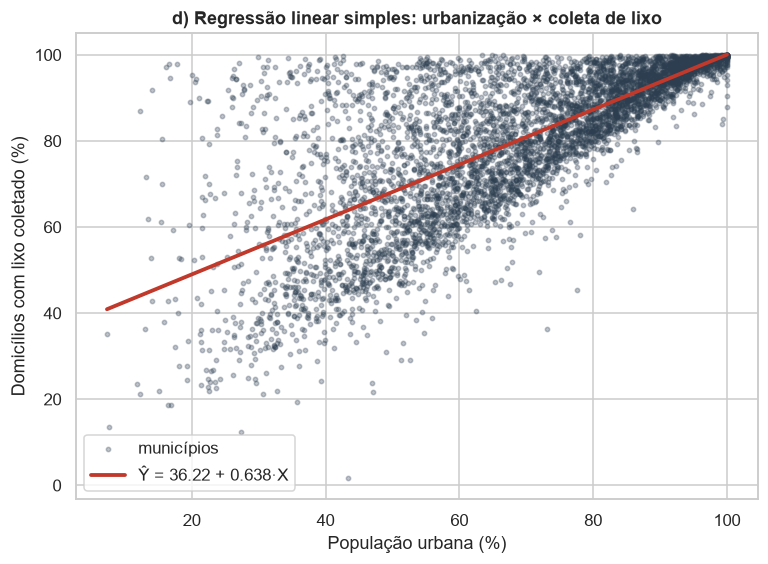

                            OLS Regression Results                            
Dep. Variable:      pct_lixo_coletado   R-squared:                       0.547
Model:                            OLS   Adj. R-squared:                  0.547
Method:                 Least Squares   F-statistic:                     6685.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:53:48   Log-Likelihood:                -21460.
No. Observations:                5538   AIC:                         4.292e+04
Df Residuals:                    5536   BIC:                         4.294e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             36.2236      0.562     64.

In [12]:
Xc = sm.add_constant(x)
mod_s = sm.OLS(y, Xc).fit()
b0, b1 = mod_s.params
print(f"d) Equação: Ŷ = {b0:.4f} + {b1:.4f}·X")
xx = np.linspace(x.min(), x.max(), 100)
plt.figure(figsize=(8, 5.5))
plt.scatter(x, y, s=8, alpha=.3, color="#2c3e50", label="municípios")
plt.plot(xx, b0 + b1*xx, color="#c0392b", lw=2.5, label=f"Ŷ = {b0:.2f} + {b1:.3f}·X")
plt.title("d) Regressão linear simples: urbanização × coleta de lixo")
plt.xlabel("População urbana (%)"); plt.ylabel("Domicílios com lixo coletado (%)"); plt.legend()
salvar("07_regressao_simples"); plt.show()
print(mod_s.summary())

In [13]:
print(f"e) R² = {mod_s.rsquared:.4f} | R² ajustado = {mod_s.rsquared_adj:.4f}")
print(f"   F = {mod_s.fvalue:.2f} | p-valor (F) = {mod_s.f_pvalue:.2e}")
print("   Modelo significativo a 5%?", "SIM" if mod_s.f_pvalue < 0.05 else "NÃO")

e) R² = 0.5470 | R² ajustado = 0.5469
   F = 6684.67 | p-valor (F) = 0.00e+00
   Modelo significativo a 5%? SIM


**d) e e) Interpretação:** o coeficiente angular $b_1$ indica quantos pontos percentuais a coleta de lixo aumenta, em média, para cada ponto percentual a mais de população urbana. O intercepto $b_0$ é a coleta estimada para um município hipotético 100% rural. O **R²** dá a fração da variação da coleta de lixo entre os municípios explicada só pela urbanização. O **teste F**, com p-valor ≈ 0, rejeita $H_0: \beta_1 = 0$, ou seja, o modelo é **estatisticamente significativo**. O restante da variação (1 − R²) se deve a fatores fora do modelo, como renda, gestão municipal e geografia.

In [14]:
cenarios = pd.DataFrame({"pct_pop_urbana": [40, 60, 90]})
cenarios["lixo_coletado_previsto"] = mod_s.predict(sm.add_constant(cenarios, has_constant="add"))
print("f) Previsões:")
print(cenarios.to_string(index=False))
RES["simples"] = dict(b0=b0, b1=b1, r2=mod_s.rsquared, r2_adj=mod_s.rsquared_adj, F=mod_s.fvalue,
                      pF=mod_s.f_pvalue, previsoes=cenarios.round(2).to_dict(orient="records"))

f) Previsões:
 pct_pop_urbana  lixo_coletado_previsto
             40                 61.7565
             60                 74.5229
             90                 93.6726


**f) Interpretação:** pelo modelo, um município com 40% de população urbana teria, em média, cerca de 62% dos domicílios com coleta de lixo, um com 60% teria cerca de 75%, e um município 90% urbano chegaria a cerca de 94%, perto da universalização. As previsões valem para a média dos municípios com aquele grau de urbanização e não para um município específico, e só devem ser usadas dentro da faixa observada de X.

## 5. Regressão linear múltipla (item 05)

**Pergunta:** quais fatores estruturais explicam a cobertura de esgoto?
- $Y$ = `pct_esgoto_rede` (% de domicílios ligados à rede de esgoto)
- $X_1$ = `pct_pop_urbana`, $X_2$ = `taxa_alfabetizacao`, $X_3$ = `log_densidade` (log10 hab/km²)

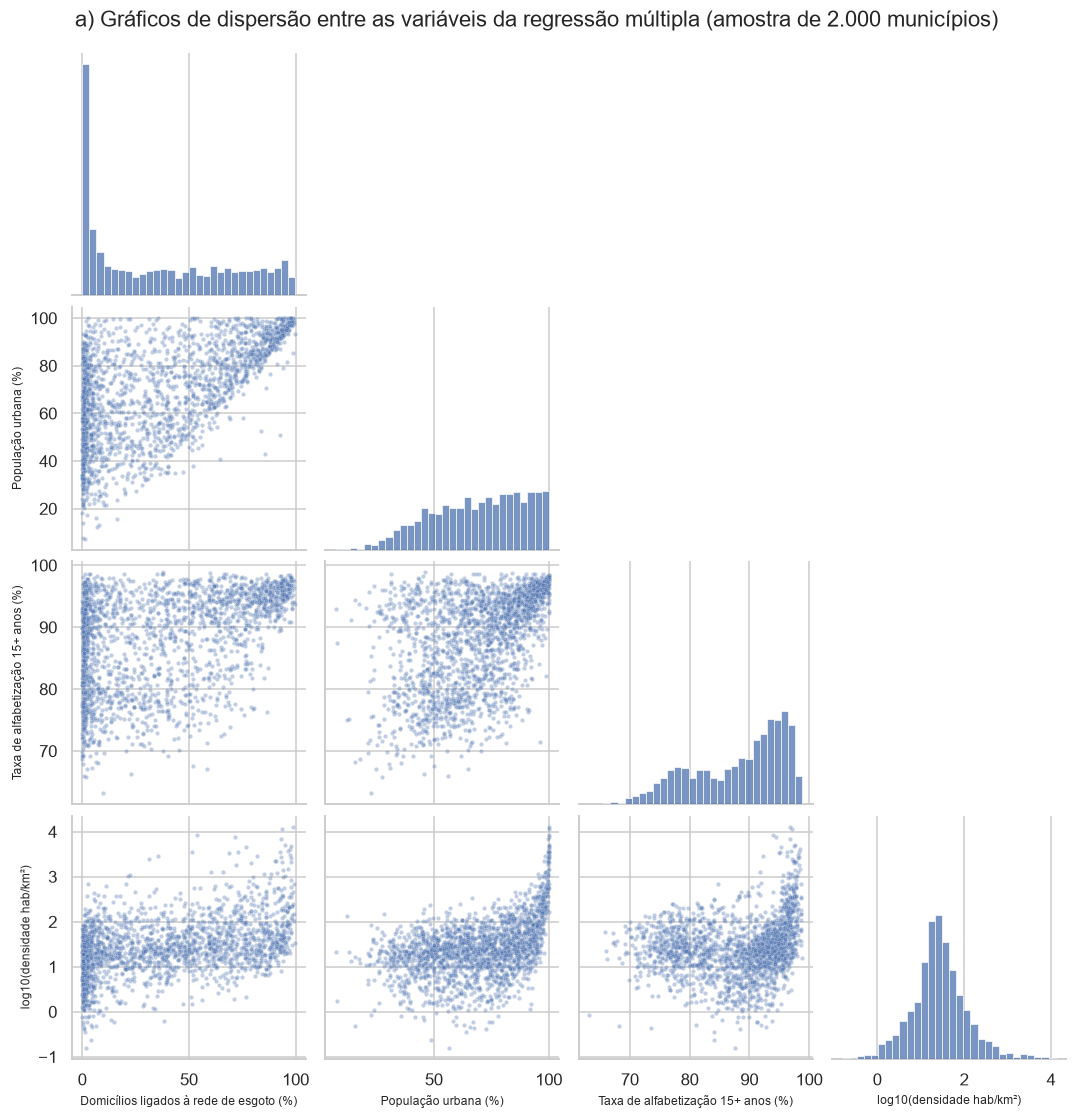

In [15]:
MULT = ["pct_esgoto_rede", "pct_pop_urbana", "taxa_alfabetizacao", "log_densidade"]
g = sns.pairplot(df[MULT].sample(2000, random_state=1), corner=True, plot_kws=dict(s=8, alpha=.35),
                 diag_kws=dict(bins=30))
g.fig.suptitle("a) Gráficos de dispersão entre as variáveis da regressão múltipla (amostra de 2.000 municípios)", y=1.02)
for axrow in g.axes:
    for a in axrow:
        if a is not None:
            a.set_xlabel(ROTULOS.get(a.get_xlabel(), a.get_xlabel()), fontsize=8)
            a.set_ylabel(ROTULOS.get(a.get_ylabel(), a.get_ylabel()), fontsize=8)
salvar("08_dispersao_multipla"); plt.show()

**a) Interpretação:** a cobertura de esgoto (primeira linha/coluna) cresce com as três variáveis explicativas. A relação é mais nítida com a urbanização e a densidade. Os pontos se acumulam perto de 0% de esgoto em todas as faixas, o que mostra que **muitos municípios não têm rede alguma**, até alguns urbanizados. As explicativas também se relacionam entre si (urbanização × densidade), e por isso é preciso checar a multicolinearidade.

In [16]:
print("b) Matriz de covariância:")
display(df[MULT].cov().round(3))
print("   Matriz de correlação de Pearson:")
corr_m = df[MULT].corr()
display(corr_m.round(3))
RES["corr_mult"] = corr_m.round(3).to_dict()

b) Matriz de covariância:


,pct_esgoto_rede,pct_pop_urbana,taxa_alfabetizacao,log_densidade
pct_esgoto_rede,"1,087.8700",399.8170,101.9960,8.8700
pct_pop_urbana,399.8170,403.0020,69.9990,5.4740
taxa_alfabetizacao,101.9960,69.9990,56.9060,0.9410
log_densidade,8.8700,5.4740,0.9410,0.3950


   Matriz de correlação de Pearson:


,pct_esgoto_rede,pct_pop_urbana,taxa_alfabetizacao,log_densidade
pct_esgoto_rede,1.0000,0.6040,0.4100,0.4280
pct_pop_urbana,0.6040,1.0000,0.4620,0.4340
taxa_alfabetizacao,0.4100,0.4620,1.0000,0.1980
log_densidade,0.4280,0.4340,0.1980,1.0000


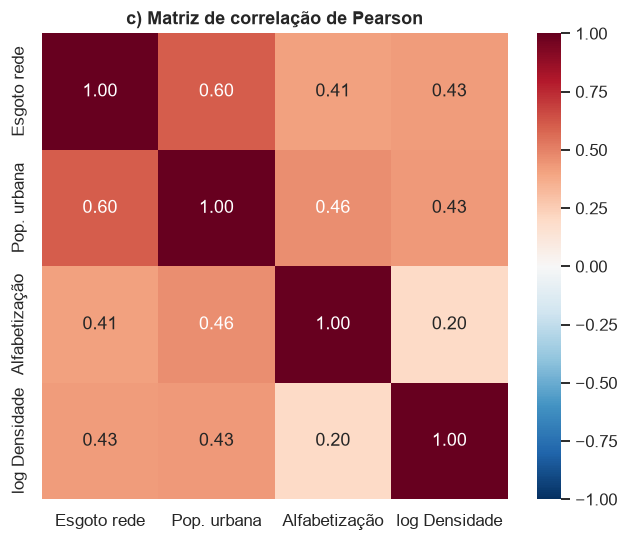

In [17]:
plt.figure(figsize=(7, 5.5))
nomes = ["Esgoto rede", "Pop. urbana", "Alfabetização", "log Densidade"]
sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            xticklabels=nomes, yticklabels=nomes)
plt.title("c) Matriz de correlação de Pearson")
salvar("09_correlacao_multipla"); plt.show()

**b) e c) Interpretação:** as covariâncias são todas positivas, então as variáveis crescem juntas, mas a escala depende das unidades. Na matriz de correlação, a cobertura de esgoto tem correlação **moderada** com urbanização (≈ 0,60), alfabetização (≈ 0,41) e densidade (≈ 0,43). Entre as explicativas, as correlações são de no máximo ≈ 0,46, o que indica **multicolinearidade baixa a moderada** (confirmada pelo VIF abaixo). Cada variável traz informação própria ao modelo.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xm = sm.add_constant(df[MULT[1:]])
mod_m = sm.OLS(df["pct_esgoto_rede"], Xm).fit()
c = mod_m.params
eq = (f"Ŷ = {c['const']:.4f} + {c['pct_pop_urbana']:.4f}·PopUrbana + "
      f"{c['taxa_alfabetizacao']:.4f}·Alfabetização + {c['log_densidade']:.4f}·log10(Densidade)")
print("d) Equação da regressão linear múltipla:\n  ", eq)
vif = pd.Series([variance_inflation_factor(Xm.values, i) for i in range(1, Xm.shape[1])], index=MULT[1:], name="VIF")
print("\nVIF:\n", vif.round(2).to_string())
print(mod_m.summary())

d) Equação da regressão linear múltipla:
   Ŷ = -91.3619 + 0.7195·PopUrbana + 0.7297·Alfabetização + 10.7373·log10(Densidade)

VIF:
 pct_pop_urbana       1.5000
taxa_alfabetizacao   1.2700
log_densidade        1.2300
                            OLS Regression Results                            
Dep. Variable:        pct_esgoto_rede   R-squared:                       0.420
Model:                            OLS   Adj. R-squared:                  0.420
Method:                 Least Squares   F-statistic:                     1338.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:53:49   Log-Likelihood:                -25708.
No. Observations:                5538   AIC:                         5.142e+04
Df Residuals:                    5534   BIC:                         5.145e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                   

In [19]:
print(f"e) R² = {mod_m.rsquared:.4f} | R² ajustado = {mod_m.rsquared_adj:.4f}")
print(f"   F = {mod_m.fvalue:.2f} | p-valor (F) = {mod_m.f_pvalue:.2e}")
print("   p-valores dos coeficientes:\n", mod_m.pvalues.apply(lambda v: f"{v:.2e}").to_string())

e) R² = 0.4204 | R² ajustado = 0.4201
   F = 1338.02 | p-valor (F) = 0.00e+00
   p-valores dos coeficientes:
 const                 3.01e-108
pct_pop_urbana        3.40e-241
taxa_alfabetizacao     1.48e-46
log_densidade          1.29e-70


**d) e e) Interpretação:** os três coeficientes são positivos e significativos (p < 0,05). **Mantidas as demais variáveis constantes**, cada ponto percentual a mais de população urbana ou de alfabetização aumenta a cobertura de esgoto esperada, e multiplicar a densidade por 10 (log10 + 1) também a eleva. O **teste F** rejeita a hipótese de que todos os coeficientes sejam nulos, então o modelo é globalmente significativo. O **R²** fica em torno de 0,4: o modelo explica parte relevante, mas não a maior parte, da variação do esgoto. Isso faz sentido, porque a existência de rede depende também de investimento histórico, de companhias estaduais de saneamento e de fatores geográficos que o modelo não inclui.

In [20]:
novos = pd.DataFrame({
    "pct_pop_urbana": [50, 85, 85],
    "taxa_alfabetizacao": [80, 95, 95],
    "log_densidade": [np.log10(15), np.log10(15), np.log10(300)],
}, index=["Município A (rural, baixa alfabetização)", "Município B (urbano, alfabetizado, pouco denso)",
          "Município C (urbano, alfabetizado, denso)"])
novos["esgoto_previsto_%"] = mod_m.predict(sm.add_constant(novos, has_constant="add"))
print("f) Previsões (3 variáveis explicativas):")
display(novos.round(2))
RES["multipla"] = dict(params=c.to_dict(), pvalues=mod_m.pvalues.to_dict(), r2=mod_m.rsquared,
                       r2_adj=mod_m.rsquared_adj, F=mod_m.fvalue, pF=mod_m.f_pvalue, eq=eq,
                       vif=vif.to_dict(), previsoes=novos.round(2).reset_index().to_dict(orient="records"))

f) Previsões (3 variáveis explicativas):


,pct_pop_urbana,taxa_alfabetizacao,log_densidade,esgoto_previsto_%
"Município A (rural, baixa alfabetização)",50,80,1.1800,15.6200
"Município B (urbano, alfabetizado, pouco denso)",85,95,1.1800,51.7500
"Município C (urbano, alfabetizado, denso)",85,95,2.4800,65.7200


**f) Interpretação:** a previsão compara perfis típicos. Um município rural e com baixa alfabetização (A) teria cobertura de esgoto bem abaixo da média nacional. Um município urbano e alfabetizado (B) ficaria bem acima, e um com o mesmo perfil e alta densidade (C) teria a maior cobertura prevista. Para políticas públicas, isso indica que **municípios pequenos, rurais e dispersos** precisam de soluções diferentes da rede convencional (por exemplo, fossas sépticas adequadas e sistemas descentralizados), já que a rede custa mais por domicílio onde a densidade é baixa.

## 6. Regressão logística binária (item 06)

**Pergunta:** é possível classificar um município como tendo esgoto adequado (≥ 50% dos domicílios ligados à rede) a partir do seu perfil?
- $Y$ = `esgoto_adequado` (1 = sim, 0 = não)
- Explicativas: `pct_pop_urbana`, `taxa_alfabetizacao`, `log_densidade`, `log_pib_per_capita`

A base foi dividida em **70% treino / 30% teste** (estratificada, `random_state=42`). O modelo é ajustado no treino e avaliado no teste.

In [21]:
LOG_X = ["pct_pop_urbana", "taxa_alfabetizacao", "log_densidade", "log_pib_per_capita"]
treino, teste = train_test_split(df, test_size=0.3, random_state=42, stratify=df["esgoto_adequado"])
mod_l = sm.Logit(treino["esgoto_adequado"], sm.add_constant(treino[LOG_X])).fit(disp=0)
bl = mod_l.params
eq_l = (f"logit(p) = {bl['const']:.4f} + {bl['pct_pop_urbana']:.4f}·PopUrbana + {bl['taxa_alfabetizacao']:.4f}·Alfabetização"
        f" + {bl['log_densidade']:.4f}·log10(Densidade) + {bl['log_pib_per_capita']:.4f}·log10(PIBpc)")
print("a) Equação da regressão logística binária:")
print("  ", eq_l)
print("   p = 1 / (1 + e^(−logit(p)))")
print(mod_l.summary())
odds = np.exp(bl).rename("razao_de_chances")
print("\nRazões de chance (odds ratio):\n", odds.round(4).to_string())

a) Equação da regressão logística binária:
   logit(p) = -10.2194 + 0.0685·PopUrbana + 0.0975·Alfabetização + 0.5254·log10(Densidade) + -1.0616·log10(PIBpc)
   p = 1 / (1 + e^(−logit(p)))
                           Logit Regression Results                           
Dep. Variable:        esgoto_adequado   No. Observations:                 3876
Model:                          Logit   Df Residuals:                     3871
Method:                           MLE   Df Model:                            4
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                  0.3207
Time:                        14:53:49   Log-Likelihood:                -1747.1
converged:                       True   LL-Null:                       -2572.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const 

**a) Interpretação:** todos os coeficientes são significativos (p < 0,001). A **razão de chances** $e^{\beta}$ diz por quanto as chances de esgoto adequado são multiplicadas por unidade a mais da variável, mantidas as demais:
- **+1 p.p. de população urbana** → chances × 1,071 (+7,1%);
- **+1 p.p. de alfabetização** → chances × 1,102 (+10,2%);
- **densidade 10 vezes maior** → chances × 1,69;
- **PIB per capita 10 vezes maior** → chances × 0,35. O sinal **negativo** surpreende, mas tem explicação: com urbanização, alfabetização e densidade fixas, os PIB per capita mais altos aparecem em municípios do agronegócio, da mineração e de energia (muitos no Centro-Oeste e no Norte), que geram muita riqueza sem que ela se traduza em rede de esgoto. Ou seja, **PIB alto não garante saneamento**.

b) Matriz de confusão (linhas = real, colunas = previsto):
 [[861 171]
 [209 421]]
   Acurácia = 0.7714 | Sensibilidade = 0.6683 | Especificidade = 0.8343 | Precisão = 0.7111
   Acurácia de referência (sempre prever a classe majoritária 0) = 0.6209


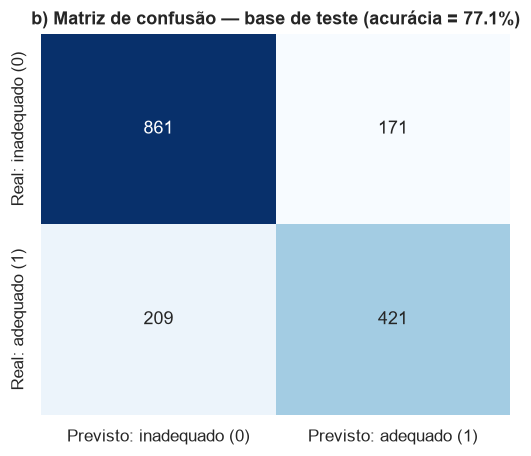

In [22]:
prob_teste = mod_l.predict(sm.add_constant(teste[LOG_X]))
pred = (prob_teste >= 0.5).astype(int)
cm = confusion_matrix(teste["esgoto_adequado"], pred)
acc = accuracy_score(teste["esgoto_adequado"], pred)
sens = recall_score(teste["esgoto_adequado"], pred)
espec = cm[0, 0] / cm[0].sum()
prec = precision_score(teste["esgoto_adequado"], pred)
base_line = 1 - teste["esgoto_adequado"].mean()
print("b) Matriz de confusão (linhas = real, colunas = previsto):\n", cm)
print(f"   Acurácia = {acc:.4f} | Sensibilidade = {sens:.4f} | Especificidade = {espec:.4f} | Precisão = {prec:.4f}")
print(f"   Acurácia de referência (sempre prever a classe majoritária 0) = {base_line:.4f}")

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Previsto: inadequado (0)", "Previsto: adequado (1)"],
            yticklabels=["Real: inadequado (0)", "Real: adequado (1)"])
plt.title(f"b) Matriz de confusão — base de teste (acurácia = {acc:.1%})")
salvar("10_matriz_confusao"); plt.show()

**b) Interpretação:** dos 1.662 municípios de teste, o modelo acertou 861 com esgoto inadequado (verdadeiros negativos) e 421 com esgoto adequado (verdadeiros positivos), uma **acurácia de 77,1%**. Esse valor supera os 62,1% de um "modelo ingênuo" que sempre preveria "inadequado". A **especificidade (83,4%)** é maior que a **sensibilidade (66,8%)**: o modelo identifica bem os municípios com déficit (o grupo prioritário para política pública), mas classifica como inadequados cerca de 1/3 dos municípios que na verdade têm boa cobertura. Esses casos costumam ser municípios pequenos que, apesar do perfil desfavorável, receberam investimento em rede.

In [23]:
perfis = pd.DataFrame({
    "pct_pop_urbana": [45, 70, 92],
    "taxa_alfabetizacao": [78, 90, 96],
    "log_densidade": [np.log10(12), np.log10(40), np.log10(500)],
    "log_pib_per_capita": [np.log10(12000), np.log10(25000), np.log10(50000)],
}, index=["Perfil 1: rural, baixa alfabetização e renda",
          "Perfil 2: intermediário",
          "Perfil 3: urbano, denso, alfabetizado e de renda alta"])
perfis["prob_esgoto_adequado"] = mod_l.predict(sm.add_constant(perfis, has_constant="add"))
perfis["classificacao"] = np.where(perfis["prob_esgoto_adequado"] >= 0.5, "1 - Adequado", "0 - Inadequado")
print("c) Classificação de novos municípios (4 variáveis explicativas, ponto de corte 0,5):")
display(perfis.round(4))
RES["logistica"] = dict(params=bl.to_dict(), pvalues=mod_l.pvalues.to_dict(), odds=odds.to_dict(), eq=eq_l,
                        pseudo_r2=mod_l.prsquared, cm=cm.tolist(), acuracia=acc, sensibilidade=sens,
                        especificidade=espec, precisao=prec, baseline=base_line,
                        n_treino=len(treino), n_teste=len(teste),
                        perfis=perfis.round(4).reset_index().to_dict(orient="records"))

c) Classificação de novos municípios (4 variáveis explicativas, ponto de corte 0,5):


,pct_pop_urbana,taxa_alfabetizacao,log_densidade,log_pib_per_capita,prob_esgoto_adequado,classificacao
"Perfil 1: rural, baixa alfabetização e renda",45,78,1.0792,4.0792,0.0357,0 - Inadequado
Perfil 2: intermediário,70,90,1.6021,4.3979,0.3829,0 - Inadequado
"Perfil 3: urbano, denso, alfabetizado e de renda alta",92,96,2.6990,4.6990,0.8666,1 - Adequado


**c) Interpretação:** o modelo devolve a **probabilidade** de o município ter esgoto adequado e classifica como 1 quando ela é ≥ 0,5. O perfil rural, com baixa alfabetização e baixa renda, fica com probabilidade muito baixa (classe 0), e o perfil urbano, denso e de renda alta fica com probabilidade alta (classe 1). Na prática, o modelo pode servir como **ferramenta de triagem** para apontar municípios com maior risco de déficit de esgoto, mas não substitui dados locais de cobertura.

In [24]:
def conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    raise TypeError(type(o))
(RAIZ / "reports" / "resultados.json").write_text(json.dumps(RES, default=conv, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resultados salvos em reports/resultados.json")

Resultados salvos em reports/resultados.json


## 7. Síntese e limitações

**Principais resultados**
1. O esgoto é o serviço de saneamento menos universalizado: em média, só cerca de 38% dos domicílios de cada município estão ligados à rede, contra cerca de 72% para água e 80% para coleta de lixo. A desigualdade regional é forte, com Norte e Nordeste nas piores posições.
2. A urbanização está fortemente associada à coleta de lixo (r ≈ 0,74) e explica mais da metade da sua variação entre municípios.
3. Urbanização, alfabetização e densidade explicam juntas cerca de 40% da variação da cobertura de esgoto. Todos os efeitos são positivos e significativos.
4. A regressão logística classifica corretamente 77% dos municípios do teste quanto a ter ou não esgoto adequado (contra 62% do modelo ingênuo) e pode servir para priorizar territórios. Um PIB per capita mais alto, por si só, não aumenta a chance de esgoto adequado.

**Limitações**
- Estudo **observacional e transversal** (um único momento): as associações encontradas **não provam causalidade**.
- O PIB é de 2021 e a população é de 2022 (o último PIB municipal com VAB por atividade disponível no SIDRA no momento da coleta), uma pequena defasagem temporal.
- As hipóteses de normalidade (itens 02 e 03) são **aproximações**: várias variáveis são assimétricas.
- A regressão linear tem **heterocedasticidade** e resíduos não normais (a variável resposta é limitada entre 0% e 100%). Os coeficientes continuam úteis como descrição, mas os intervalos e testes devem ser vistos com cautela.
- O limiar de 50% para "esgoto adequado" é uma escolha analítica. Outros limiares mudariam a classificação.
- A unidade de análise é o município: os resultados **não** valem automaticamente para domicílios ou pessoas (falácia ecológica).